In [2]:
# 数値計算や配列操作を効率的に行うためのNumPyライブラリをインポートする
import numpy as np

# グラフ描画を行うためのMatplotlibのpyplotモジュールをインポートする
import matplotlib.pyplot as plt

# 存在しないキーにアクセスした際にデフォルト値を返す辞書を作成するためのdefaultdictをインポートする
from collections import defaultdict

# --- 定数の設定 ---

# 学習を行う総エピソード（ゲームの試行回数）数を10万回に設定する
EPISODES = 100000

# 学習率（Q値の更新の度合い）を0.01に設定する
ALPHA = 0.01

# 割引率（将来の報酬の価値の重み）を0.9に設定する
GAMMA = 0.9

# ε-greedy法の初期イプシロン（ランダムに行動する確率）を1.0（100%）に設定する
INITIAL_EPSILON = 1.0

# エピソードが進むにつれてイプシロンを減少させる減衰量を計算する（総エピソードの1/10の期間で減衰）
EPSILON_DECAY = INITIAL_EPSILON / (EPISODES / 10)

# イプシロンの最小値を0.1（10%）に設定する（常に一定の確率で探索を続けるため）
FINAL_EPSILON = 0.1


# 1デッキ分のトランプ（カードの数値リスト）を作成してシャッフルする関数
def create_deck():
    # 1から10（10は絵札を含めて4枚）までのカードを持つリストを作成する（ブラックジャックの仕様）
    deck = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10, 10, 10] * 4

    # デッキのカードの順番をランダムに入れ替える
    np.random.shuffle(deck)

    # シャッフルされたデッキを返す
    return deck


# 手札の合計値を計算する関数（エースの扱いを考慮）
def sum_hand(hand):
    # 手札のすべてのカードの数値を合計する
    total = sum(hand)

    # 手札にエース（1）が含まれており、かつ11として計算しても21を超えない場合
    if 1 in hand and total + 10 <= 21:
        # エースを11として扱うため、合計に10を加算して返す
        return total + 10

    # エースを1として扱う場合はそのままの合計を返す
    return total


# ゲーム開始時にプレイヤーとディーラーの手札を配り、環境をリセットする関数
def reset_env(deck):
    # デッキから2枚ずつカードをポップして、プレイヤーとディーラーの手札を配る
    player_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    # ゲームが終了したかどうかを表すフラグを False に設定する
    done = False

    # 更新されたデッキ、プレイヤーの手札、ディーラーの手札、終了フラグを返す
    return deck, player_hand, dealer_hand, done


# 現在の手札状況から強化学習の状態（State）を表現するタプルを取得する関数
def get_state(player_hand, dealer_hand):
    # 手札にエースが含まれており、かつ11として計算しても21を超えないusable ace（使えるエース）の状態か判定する
    usable_ace = 1 in player_hand and sum(player_hand) + 10 <= 21

    # 「プレイヤーの手札の合計値、ディーラーの最初のカードの数値、usable aceの有無」のタプルを状態として返す
    return (sum_hand(player_hand), dealer_hand[0], usable_ace)


# ε-greedy法に基づいて次の行動（0: スタンド, 1: ヒット）を決定する関数
def choose_action(state, q_table, epsilon):
    # 0から1までの乱数がイプシロン未満の場合は、ランダムに行動を選ぶ（探索）
    if np.random.uniform(0, 1) < epsilon:
        return np.random.choice([0, 1])

    # そうでない場合は、Qテーブルを参照して最も評価値（Q値）が高い行動を選ぶ（利用）
    else:
        return np.argmax(q_table[state])


# プレイヤーの選択した行動に応じて環境を1ステップ進め、次の状態と報酬を返す関数
def step_env(deck, player_hand, dealer_hand, action):
    # 行動が 1（ヒット：カードを1枚引く）の場合
    if action == 1:
        # デッキからカードを1枚引いてプレイヤーの手札に追加する
        player_hand.append(deck.pop())

        # 手札の合計が21を超えた場合（バースト）
        if sum_hand(player_hand) > 21:
            # 報酬 -1（負け）を返し、ゲーム終了フラグを True にする
            return deck, player_hand, dealer_hand, -1, True

    # 行動が 0（スタンド：カードを引くのをやめる）の場合
    if action == 0:
        # ディーラーは手札の合計が17未満の間、カードを自動的に引き続けるルール
        while sum_hand(dealer_hand) < 17:
            dealer_hand.append(deck.pop())

        # プレイヤーとディーラーの最終的な手札の合計値を計算する
        player_sum = sum_hand(player_hand)
        dealer_sum = sum_hand(dealer_hand)

        # ディーラーがバーストした、またはプレイヤーの合計の方が大きい場合（プレイヤーの勝ち）
        if dealer_sum > 21 or player_sum > dealer_sum:
            return deck, player_hand, dealer_hand, 1, True

        # プレイヤーの合計の方が小さい場合（ディーラーの勝ち）
        elif player_sum < dealer_sum:
            return deck, player_hand, dealer_hand, -1, True

        # 双方が同点の場合（引き分け）
        else:
            return deck, player_hand, dealer_hand, 0, True

    # ゲームが継続中の場合
    return deck, player_hand, dealer_hand, 0, False


# Q学習のアルゴリズムに基づいてQテーブル（状態行動価値関数）を更新する関数
def update_q_table(q_table, state, action, reward, next_state, done, alpha, gamma):
    # ゲームが終了している場合は次の状態の価値を0とし、終了していなければ次の状態での最大Q値を取得する
    best_next_action = 0 if done else np.max(q_table[next_state])

    # 報酬と割引率を考慮したTDターゲット（目標価値）を計算する
    td_target = reward + gamma * best_next_action

    # 現在のQ値とTDターゲットの差分（TD誤差）を計算する
    td_error = td_target - q_table[state][action]

    # 学習率（alpha）を掛け合わせて、Qテーブルの該当する状態・行動の値を更新する
    q_table[state][action] += alpha * td_error


# エージェントの学習全体のループを管理するメイン関数
def train_agent(episodes, alpha, initial_epsilon, epsilon_decay, final_epsilon, gamma):
    # 各状態・行動ペアのQ値を保存するQテーブルを初期化する（初期値は0）
    q_table = defaultdict(lambda: np.zeros(2))

    # 各エピソードごとの報酬を記録するリストを初期化する
    episode_rewards = []

    # イプシロンの値を初期値に設定する
    epsilon = initial_epsilon

    # 指定されたエピソード数だけゲームの試行を繰り返す
    for episode in range(episodes):
        # カードデッキを作成・シャッフルする
        deck = create_deck()

        # ゲーム環境をリセットして初期手札を配る
        deck, player_hand, dealer_hand, done = reset_env(deck)

        # 現在の状態を取得する
        state = get_state(player_hand, dealer_hand)

        # そのエピソードでの累積報酬を0に初期化する
        total_reward = 0

        # 1ゲームが終了するまでループする
        while not done:
            # 現在の状態とイプシロンに基づいて行動を選択する
            action = choose_action(state, q_table, epsilon)

            # 選択した行動を実行し、次の環境の状態と報酬を受け取る
            deck, player_hand, dealer_hand, reward, done = step_env(deck, player_hand, dealer_hand, action)

            # 次の状態を取得する
            next_state = get_state(player_hand, dealer_hand)

            # 得られた結果をもとにQテーブルを更新する
            update_q_table(q_table, state, action, reward, next_state, done, alpha, gamma)

            # 状態を次の状態に更新する
            state = next_state

            # 得られた報酬を累積報酬に加算する
            total_reward += reward

        # 1エピソード終了ごとに、イプシロンを徐々に減衰させる（ただし下限は final_epsilon まで）
        epsilon = max(final_epsilon, epsilon - epsilon_decay)

        # そのエピソードの累積報酬を記録する
        episode_rewards.append(total_reward)

    # 学習済みのQテーブルと、各エピソードの報酬の履歴を返す
    return q_table, episode_rewards


# 設定した定数を用いてエージェントの学習を実行し、Qテーブルと報酬の履歴を受け取る
q_table, episode_rewards = train_agent(EPISODES, ALPHA, INITIAL_EPSILON, EPSILON_DECAY, FINAL_EPSILON, GAMMA)

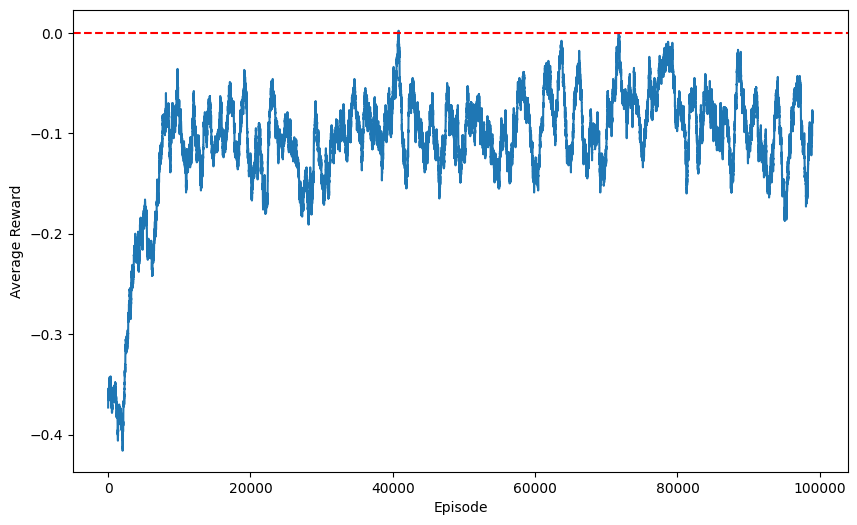

In [4]:
# --- 報酬の移動平均を計算 ---
# 移動平均を計算するためのウィンドウサイズ（平均を計算するエピソードの範囲）を1000回に設定する
window_size = 1000
# 計算した移動平均の値を格納するための空のリストを準備する
averages=[]
# 全エピソードの報酬データから、ウィンドウサイズ分の区切りを取り出しながら最後までループを回す
for i in range(len(episode_rewards)-window_size+1):
    # 現在の位置からウィンドウサイズ分（1000回分）の報酬のリストを切り出す
    window = episode_rewards[i:i + window_size]
    # 切り出した1000回分の報酬の合計をウィンドウサイズで割り、平均値を計算する
    window_average=sum(window)/window_size
    # 計算した平均値を averages リストに追加する
    averages.append(window_average)

# --- 移動平均をプロット ---
# グラフを描画するための新しいウィンドウを作成し、大きさを「横10インチ、縦6インチ」に指定する
plt.figure(figsize=(10,6))
# 計算した移動平均の推移を折れ線グラフとしてプロットする
plt.plot(averages)
# 勝ち負けの基準（プラスとマイナスの境界）となる y = 0 の位置に、赤い破線（水平線）を描画する
plt.axhline(0,color="red",linestyle="--")
# グラフのX軸に「Episode（エピソード数）」というラベルを設定する
plt.xlabel("Episode")
# グラフのY軸に「Average Reward（平均報酬）」というラベルを設定する
plt.ylabel("Average Reward")
# 設定したグラフ画面を画面上に表示する
plt.show()


In [6]:
# 学習済みのエージェント（Qテーブル）を用いて、1回だけ実際にゲームをプレイして経過と結果を表示する関数を定義する
def play_one_episode(q_table,epsilon=0.0):
    # 新しいカードデッキを作成してシャッフルする
    deck = create_deck()
    # ゲーム環境を初期化し、プレイヤーとディーラーに初期手札を配る
    deck,player_hand,dealer_hand,done=reset_env(deck)
    # 初期手札から現在の状態（State）を取得する
    state=get_state(player_hand,dealer_hand)

    # ゲーム開始時のプレイヤーの手札と、ディーラーの最初のカードを画面に表示する
    print(f"initial player hand: {player_hand}, dealer hand: {dealer_hand[0]}")

    # ゲームが終了（doneがTrue）するまでループを回す
    while not done:
        # 現在の状態とQテーブル、およびイプシロン（引数で指定、デフォルトは0.0=完全な最適行動の利用）に基づいて次の行動を選択する
        action = choose_action(state,q_table,epsilon)
        # 選択した行動の数値（1: ヒット, 0: スタンド）を、人間が読みやすい文字列に変換する
        action_str = "Hit" if action == 1 else "Stand"
        # プレイヤーがどちらの行動を選んだのかを画面に表示する
        print(f"Player action: {action_str}")

        # 選択した行動を環境に反映させ、次の手札の状態、報酬、および終了フラグを受け取る
        deck, player_hand, dealer_hand, reward, done = step_env(deck, player_hand, dealer_hand, action)
        # 行動後の新しい状態を取得する
        state = get_state(player_hand, dealer_hand)

        # 行動後のプレイヤーの手札と、ディーラーの最初のカードの状態を画面に表示する
        print(f"player hand: {player_hand}, dealer hand: {dealer_hand[0]}")

    # ゲーム終了時の報酬が 1 の場合は、結果を "Win（勝ち）" に設定する
    if reward == 1:
       result ="Win"

    # 報酬が -1 の場合は、結果を "Lose（負け）" に設定する
    elif reward == -1:
       result = "Lose"

    # それ以外（報酬が0）の場合は、結果を "Draw（引き分け）" に設定する
    else:
      result = "Draw"


    # ゲーム終了時のプレイヤーの最終手札、ディーラーのすべての手札、および勝敗の結果を画面に表示する
    print(f"Final player hand: {player_hand}, Final dealer hand: {dealer_hand}, result: {result}")



# 学習済みのQテーブルを関数に引き渡して、エージェントに実際に1回ブラックジャックをプレイさせる
play_one_episode(q_table)

initial player hand: [6, 5], dealer hand: 2
Player action: Hit
player hand: [6, 5, 8], dealer hand: 2
Player action: Stand
player hand: [6, 5, 8], dealer hand: 2
Final player hand: [6, 5, 8], Final dealer hand: [2, 1, 7], result: Lose


In [7]:
# エージェントがエピソードと実行する関数
play_one_episode(q_table)

initial player hand: [5, 10], dealer hand: 10
Player action: Hit
player hand: [5, 10, 6], dealer hand: 10
Player action: Stand
player hand: [5, 10, 6], dealer hand: 10
Final player hand: [5, 10, 6], Final dealer hand: [10, 8], result: Win


In [8]:
# エージェントがエピソードと実行する関数
play_one_episode(q_table)

initial player hand: [1, 5], dealer hand: 5
Player action: Hit
player hand: [1, 5, 10], dealer hand: 5
Player action: Stand
player hand: [1, 5, 10], dealer hand: 5
Final player hand: [1, 5, 10], Final dealer hand: [5, 6, 6], result: Lose


In [9]:
# エージェントがエピソードと実行する関数
play_one_episode(q_table)

initial player hand: [8, 10], dealer hand: 3
Player action: Stand
player hand: [8, 10], dealer hand: 3
Final player hand: [8, 10], Final dealer hand: [3, 9, 3, 2], result: Win


In [10]:
# 未学習の（すべてのQ値が0で初期化された）新しいQテーブルを作成する
q_table = defaultdict(lambda: np.zeros(2))
# 学習を一切行っていない初期状態のQテーブルを関数に渡し、エージェントに1回ゲームをプレイさせて様子を確認する
play_one_episode(q_table)

initial player hand: [10, 5], dealer hand: 10
Player action: Stand
player hand: [10, 5], dealer hand: 10
Final player hand: [10, 5], Final dealer hand: [10, 4, 1, 3], result: Lose
